# Bài 10 · Tinh chỉnh PhoBERT cho phân loại cảm xúc (dữ liệu thật)

**Thời lượng gợi ý:** 240 phút · **Cần:** Bài 8, Bài 9 · **Nên có GPU** (≥ 4 GB VRAM; chạy CPU rất chậm) · **Cần Internet** lần đầu

## Mục tiêu

1. Hiểu **tinh chỉnh (fine-tuning)** là gì: lấy mô hình tiền huấn luyện, thêm "đầu" phân loại, huấn luyện tiếp trên dữ liệu có nhãn.
2. Chuẩn bị dữ liệu **đúng quy trình PhoBERT**: tách từ → tokenizer → đệm động.
3. Viết **vòng huấn luyện** hoàn chỉnh: AdamW, warmup + giảm tuyến tính, huấn luyện độ chính xác hỗn hợp (fp16), cắt gradient, chọn checkpoint trên valid.
4. Đánh giá **trung thực**: so với baseline TF-IDF, báo cáo từng lớp, phân tích lỗi, thử trên dữ liệu khác miền.
5. Lưu mô hình, viết **thẻ mô hình**, nạp lại và kiểm tra.

> Bài này tương ứng **Chương 3 (Tinh chỉnh một mô hình huấn luyện trước)** của [khóa Hugging Face tiếng Việt](https://huggingface.co/docs/course/vi/chapter3/1). Ta viết vòng lặp bằng tay để thấy từng bước; cuối bài có phiên bản `Trainer` tương đương.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import copy, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
transformers.logging.set_verbosity_error()

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from nlpvi import load_hard, load_splits, normalize, segment, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Thiết bị:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "(không có GPU: hãy giảm dữ liệu bằng MAX_TRAIN)")
if device == "cuda":
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Thiết bị: cuda | NVIDIA GeForce RTX 3050 Laptop GPU
VRAM: 4.3 GB


## 1. Dữ liệu

Ta dùng **UIT-VSFC** (*Vietnamese Students' Feedback Corpus*): ~16 nghìn câu phản hồi của sinh viên về giảng viên, chương trình đào tạo, cơ sở vật chất, gán nhãn cảm xúc *tiêu cực / trung tính / tích cực*. Dữ liệu được tải từ Hugging Face Hub **lúc chạy** (không đi kèm repo).

> ⚠️ **Giấy phép:** thẻ dữ liệu trên Hub ghi `license: unknown`. Hãy dùng cho học tập/nghiên cứu, **không** phân phối lại và kiểm tra điều khoản của tác giả gốc trước khi dùng cho mục đích khác. Đây cũng là bài học chung: *luôn biết giấy phép dữ liệu của mình*.

Dataset này dùng script cũ nên thư viện `datasets` bản mới không nạp trực tiếp; ta nạp qua nhánh `refs/convert/parquet`. Nếu mạng/nhánh không khả dụng, ô dưới tự lùi về bộ dữ liệu tổng hợp của khóa học.

In [2]:
MAX_TRAIN = None            # đặt số nguyên (ví dụ 2000) để chạy nhanh hơn / trên CPU
VI = {"negative": "tiêu cực", "neutral": "trung tính", "positive": "tích cực"}

def nap_du_lieu():
    try:
        from datasets import load_dataset
        ds = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")
        names = ds["train"].features["sentiment"].names

        def to_df(split):
            d = ds[split].to_pandas()
            return pd.DataFrame({"text": d["sentence"], "label": d["sentiment"].map(lambda i: VI[names[i]])})
        return "UIT-VSFC", to_df("train"), to_df("validation"), to_df("test")
    except Exception as e:
        print(f"[!] Không nạp được UIT-VSFC ({type(e).__name__}); dùng dữ liệu tổng hợp của khóa học.")
        tr, va, te = load_splits()
        return "tổng hợp", tr[["text", "label"]], va[["text", "label"]], te[["text", "label"]]

NGUON, train, valid, test = nap_du_lieu()
if MAX_TRAIN:
    train = train.sample(MAX_TRAIN, random_state=SEED).reset_index(drop=True)
CLASSES = sorted(train["label"].unique())
label2id = {c: i for i, c in enumerate(CLASSES)}
id2label = {i: c for c, i in label2id.items()}
print("Nguồn:", NGUON, "| train/valid/test =", len(train), len(valid), len(test))
print("Lớp:", CLASSES)
print(pd.DataFrame({"train": train["label"].value_counts(normalize=True), "valid": valid["label"].value_counts(normalize=True),
                    "test": test["label"].value_counts(normalize=True)}).round(3).to_string())
display(train.sample(6, random_state=1))

Nguồn: UIT-VSFC | train/valid/test = 11426 1583 3166
Lớp: ['tiêu cực', 'trung tính', 'tích cực']
            train  valid   test
label                          
tích cực    0.494  0.509  0.502
tiêu cực    0.466  0.445  0.445
trung tính  0.040  0.046  0.053


,text,label
10558,"thầy giảng bài rất chi tiết , rất tận tâm !",tích cực
813,"giảng viên nhiệt tình , chắt lọc nội dung cũng...",tích cực
11128,có một đóng góp cho bộ môn anh văn trên trường...,tích cực
8046,giảng viên hỗ trợ tích cực .,tích cực
6933,"phương pháp giảng dạy phù hợp , lôi cuốn vào b...",tích cực
10385,giảng viên chưa truyền đạt bài giảng một cách ...,tiêu cực


Quan sát phân phối nhãn: nếu một lớp rất hiếm (với UIT-VSFC là *trung tính*, chỉ vài phần trăm), **accuracy sẽ che mất việc mô hình xử lý lớp đó kém** — ta sẽ báo cáo macro-F1 và từng lớp.

## 2. Baseline: TF-IDF + Logistic Regression

Trước khi dùng mô hình 135 triệu tham số, hãy biết *mốc* cần vượt. Baseline này huấn luyện trong vài giây.

In [3]:
t0 = time.time()
tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
Xtr = tf.fit_transform(train["text"].map(normalize))
lr = LogisticRegression(C=10, max_iter=3000, class_weight="balanced").fit(Xtr, train["label"])
pred_lr_te = lr.predict(tf.transform(test["text"].map(normalize)))
print(f"Huấn luyện {time.time() - t0:.0f}s")
print(f"TF-IDF + LR | test: accuracy = {accuracy_score(test['label'], pred_lr_te):.3f}, macro-F1 = {f1_score(test['label'], pred_lr_te, average='macro'):.3f}")

Huấn luyện 2s
TF-IDF + LR | test: accuracy = 0.883, macro-F1 = 0.721


## 3. Chuẩn bị đầu vào cho PhoBERT

Ba việc: **(1)** tách từ, **(2)** tokenizer thành chỉ số, **(3)** chọn độ dài tối đa hợp lý rồi **đệm động** (mỗi batch đệm theo câu dài nhất trong batch, không phải theo độ dài tối đa).

> **Lưu ý về tách từ.** PhoBERT được tiền huấn luyện trên văn bản tách từ bằng **RDRSegmenter** (VnCoreNLP, cần Java). Ở đây ta dùng bộ tách từ từ điển thuần Python (`nlpvi.segment`) cho gọn và chạy được mọi nơi. Hai bộ tách từ không hoàn toàn giống nhau, nên có thể mất một chút chất lượng so với quy trình chuẩn; hãy thay bằng RDRSegmenter (hoặc Underthesea) nếu bạn cần điểm số tối đa.

In [4]:
tok = AutoTokenizer.from_pretrained("vinai/phobert-base")

def ma_hoa(texts, max_len):
    return tok([segment(t) for t in texts], truncation=True, max_length=max_len)["input_ids"]

t0 = time.time()
lens = [len(x) for x in ma_hoa(train["text"].tolist(), max_len=256)]
print(f"Tokenize {len(train)} câu trong {time.time() - t0:.0f}s")
print("Độ dài token — TB:", round(np.mean(lens), 1), "| p95:", int(np.percentile(lens, 95)), "| p99.5:", int(np.percentile(lens, 99.5)), "| max:", max(lens))
MAX_LEN = int(min(128, np.percentile(lens, 99.5)))
print("→ MAX_LEN =", MAX_LEN, "(PhoBERT tối đa 256)")

Tokenize 11426 câu trong 2s
Độ dài token — TB: 13.5 | p95: 30 | p99.5: 55 | max: 129
→ MAX_LEN = 55 (PhoBERT tối đa 256)


In [5]:
class DS(torch.utils.data.Dataset):
    def __init__(self, df):
        self.ids = ma_hoa(df["text"].tolist(), MAX_LEN)
        self.y = [label2id[l] for l in df["label"]]
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.ids[i], self.y[i]

def collate(batch):
    ids, y = zip(*batch)
    L = max(map(len, ids))
    x = torch.full((len(ids), L), tok.pad_token_id, dtype=torch.long)
    m = torch.zeros((len(ids), L), dtype=torch.long)
    for i, s in enumerate(ids):
        x[i, :len(s)] = torch.tensor(s); m[i, :len(s)] = 1
    return x, m, torch.tensor(y)

ds_tr, ds_va, ds_te = DS(train), DS(valid), DS(test)
x, m, y = collate([ds_tr[i] for i in range(4)])
print("Một batch:", tuple(x.shape), "| mặt nạ:", m.sum(1).tolist())

Một batch: (4, 13) | mặt nạ: [6, 9, 9, 13]


## 4. Mô hình

`AutoModelForSequenceClassification` = PhoBERT + một **đầu phân loại** (lớp tuyến tính trên vector token `<s>`) được **khởi tạo ngẫu nhiên**. Thư viện sẽ in cảnh báo "một số trọng số được khởi tạo mới" — điều đó là đúng và mong đợi: đầu phân loại chưa được huấn luyện, và ta sắp huấn luyện nó cùng phần thân.

In [6]:
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    "vinai/phobert-base", num_labels=len(CLASSES), id2label=id2label, label2id=label2id).to(device)
n_tham_so = sum(p.numel() for p in model.parameters())
print(f"Tổng tham số: {n_tham_so / 1e6:.0f} triệu")
print("Đầu phân loại:", model.classifier)

Tổng tham số: 135 triệu
Đầu phân loại: RobertaClassificationHead(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (out_proj): Linear(in_features=768, out_features=3, bias=True)
)


## 5. Vòng huấn luyện

Các thành phần quan trọng:

| Thành phần | Giá trị mặc định tốt | Vì sao |
|---|---|---|
| **Learning rate** | 1e-5 → 5e-5 | tinh chỉnh dùng lr **nhỏ**: ta chỉ nhích trọng số đã tốt, không học lại từ đầu |
| **Warmup** | ~6–10% số bước đầu tăng dần lr từ 0 | tránh làm hỏng trọng số bằng các cập nhật lớn khi đầu phân loại còn ngẫu nhiên |
| **Giảm tuyến tính** | lr về 0 ở cuối | hội tụ ổn định |
| **Weight decay** | 0,01 | chuẩn hóa nhẹ |
| **Cắt gradient** | 1,0 | chống bùng nổ gradient |
| **fp16 / AMP** | bật trên GPU | nhanh hơn, tiết kiệm VRAM |
| **Số epoch** | 2–4 | tinh chỉnh quá lâu dễ quá khớp; chọn epoch tốt nhất trên **valid** |

In [7]:
EPOCHS, BATCH, LR, WARMUP = 3, 32, 3e-5, 0.1

@torch.no_grad()
def du_doan(model, ds, bs=128):
    model.eval()
    probs, ys = [], []
    for x, m, y in DataLoader(ds, batch_size=bs, collate_fn=collate):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(input_ids=x.to(device), attention_mask=m.to(device)).logits
        probs.append(logits.float().softmax(-1).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def danh_gia(model, ds):
    p, y = du_doan(model, ds)
    pred = p.argmax(1)
    return {"acc": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro")}

dl_tr = DataLoader(ds_tr, batch_size=BATCH, shuffle=True, collate_fn=collate)
tong_buoc = EPOCHS * len(dl_tr)
khong_decay = ["bias", "LayerNorm.weight"]
nhom = [{"params": [p for n, p in model.named_parameters() if not any(k in n for k in khong_decay)], "weight_decay": 0.01},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in khong_decay)], "weight_decay": 0.0}]
opt = torch.optim.AdamW(nhom, lr=LR)
sched = get_linear_schedule_with_warmup(opt, int(WARMUP * tong_buoc), tong_buoc)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
print(f"{len(dl_tr)} bước/epoch × {EPOCHS} epoch = {tong_buoc} bước")

358 bước/epoch × 3 epoch = 1074 bước


In [8]:
lich_su, best_f1, best_state = [], -1.0, None
t_all = time.time()
for ep in range(1, EPOCHS + 1):
    model.train()
    t0, tong_loss = time.time(), 0.0
    for step, (x, m, y) in enumerate(dl_tr, 1):
        x, m, y = x.to(device), m.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            loss = F.cross_entropy(model(input_ids=x, attention_mask=m).logits.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tong_loss += loss.item()
    r = danh_gia(model, ds_va)
    lich_su.append({"epoch": ep, "loss_train": tong_loss / len(dl_tr), "acc_valid": r["acc"], "macroF1_valid": r["macro_f1"], "giây": time.time() - t0})
    print(f"epoch {ep}: loss={tong_loss / len(dl_tr):.4f} | valid acc={r['acc']:.3f} macro-F1={r['macro_f1']:.3f} | {time.time() - t0:.0f}s")
    if r["macro_f1"] > best_f1:
        best_f1 = r["macro_f1"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
print(f"Tổng thời gian huấn luyện: {(time.time() - t_all) / 60:.1f} phút | macro-F1 valid tốt nhất = {best_f1:.3f}")
if device == "cuda":
    print(f"VRAM đỉnh: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

epoch 1: loss=0.3639 | valid acc=0.941 macro-F1=0.827 | 68s


epoch 2: loss=0.1577 | valid acc=0.950 macro-F1=0.851 | 68s


epoch 3: loss=0.1086 | valid acc=0.948 macro-F1=0.858 | 67s


Tổng thời gian huấn luyện: 3.4 phút | macro-F1 valid tốt nhất = 0.858
VRAM đỉnh: 3.14 GB


**Đọc quá trình huấn luyện:** loss train giảm đều theo epoch, macro-F1 valid tăng (≈0,83 → 0,85 → 0,86), nên checkpoint tốt nhất là epoch cuối. Ta vẫn viết sẵn logic "giữ checkpoint tốt nhất" vì với dữ liệu khác, valid có thể bắt đầu giảm trong khi loss train vẫn giảm — dấu hiệu quá khớp. Cũng lưu ý một sự thật nhỏ: ta chọn 1 trong 3 checkpoint dựa trên valid, nên điểm valid hơi lạc quan; điểm test (mục dưới) mới là con số trung thực.

## 6. Đánh giá trên tập test

Tập test chỉ mở **một lần**, sau khi đã chốt mô hình bằng valid.

,mô hình,accuracy,macro-F1
0,TF-IDF + Logistic Regression,0.883,0.721
1,PhoBERT tinh chỉnh,0.941,0.840


              precision    recall  f1-score   support

    tiêu cực      0.948     0.967     0.957      1409
  trung tính      0.719     0.521     0.604       167
    tích cực      0.952     0.963     0.957      1590

    accuracy                          0.941      3166
   macro avg      0.873     0.817     0.840      3166
weighted avg      0.938     0.941     0.939      3166



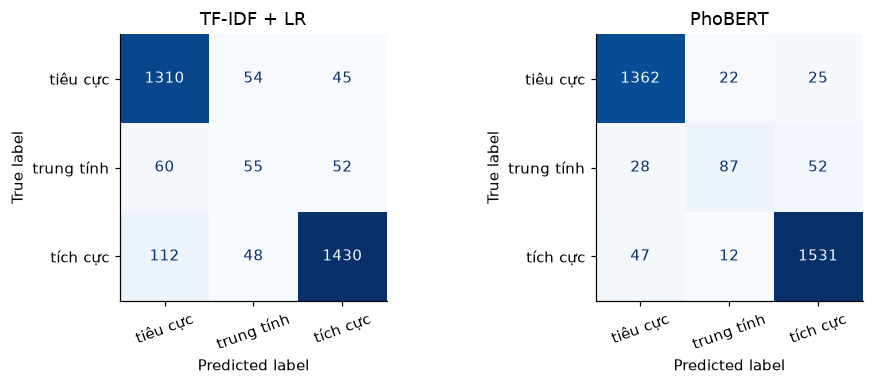

In [9]:
p_te, y_te = du_doan(model, ds_te)
pred_te = p_te.argmax(1)
pred_te_lab = [id2label[i] for i in pred_te]

kq = pd.DataFrame([
    {"mô hình": "TF-IDF + Logistic Regression", "accuracy": accuracy_score(test["label"], pred_lr_te), "macro-F1": f1_score(test["label"], pred_lr_te, average="macro")},
    {"mô hình": "PhoBERT tinh chỉnh", "accuracy": accuracy_score(test["label"], pred_te_lab), "macro-F1": f1_score(test["label"], pred_te_lab, average="macro")},
]).round(3)
display(kq)
print(classification_report(test["label"], pred_te_lab, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, pred, ten in [(ax[0], pred_lr_te, "TF-IDF + LR"), (ax[1], pred_te_lab, "PhoBERT")]:
    ConfusionMatrixDisplay.from_predictions(test["label"], pred, labels=CLASSES, ax=a, colorbar=False, cmap="Blues")
    a.set_title(ten); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Đọc kết quả.** (Các con số dưới đây là của một lần chạy trên máy biên soạn; bạn sẽ nhận được số hơi khác.)

- PhoBERT hơn TF-IDF rõ rệt: accuracy ≈0,94 so với ≈0,88 và macro-F1 ≈0,84 so với ≈0,72.
- **Lớp *trung tính* là điểm yếu**: chỉ ~5% dữ liệu, recall chỉ ≈0,52 (mô hình bỏ sót gần một nửa). Accuracy 0,94 che giấu điều này — đúng lý do ta dùng macro-F1 và đọc từng lớp.
- Mô hình gần như hoàn hảo trên hai lớp lớn (F1 ≈0,96).

## 7. Khoảng tin cậy và độ ổn định

Một lần huấn luyện = một seed. Để biết chênh lệch giữa PhoBERT và baseline có chắc chắn không, ta dùng **bootstrap trên tập test** (lấy mẫu lại các câu, tính lại macro-F1) — nó đo độ bất định do *kích thước tập test*. Nó **không** đo biến thiên do seed huấn luyện; muốn thế phải huấn luyện lại nhiều seed (mất vài chục phút mỗi seed).

In [10]:
rng = np.random.default_rng(0)
y_arr = test["label"].values
pl, pb = np.array(pred_lr_te), np.array(pred_te_lab)
diff, f_lr, f_pb = [], [], []
for _ in range(1000):
    i = rng.integers(0, len(y_arr), len(y_arr))
    a = f1_score(y_arr[i], pl[i], average="macro"); b = f1_score(y_arr[i], pb[i], average="macro")
    f_lr.append(a); f_pb.append(b); diff.append(b - a)
ci = lambda v: f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
print("macro-F1 TF-IDF + LR :", ci(f_lr))
print("macro-F1 PhoBERT     :", ci(f_pb))
print("hiệu (PhoBERT − LR)  :", ci(diff), "| tỉ lệ lần bootstrap PhoBERT hơn:", f"{np.mean(np.array(diff) > 0):.1%}")

macro-F1 TF-IDF + LR : [0.696, 0.745]
macro-F1 PhoBERT     : [0.815, 0.863]
hiệu (PhoBERT − LR)  : [0.092, 0.146] | tỉ lệ lần bootstrap PhoBERT hơn: 100.0%


## 8. Phân tích lỗi

Các câu mô hình **tự tin nhưng sai** là nơi học được nhiều nhất: đó thường là nhãn gán sai, câu mơ hồ, hoặc điểm yếu thật của mô hình.

In [11]:
conf = p_te.max(1)
sai = np.where(pred_te != y_te)[0]
sai = sai[np.argsort(-conf[sai])][:12]
for i in sai:
    print(f"[thật: {test['label'].iloc[i]:10s} | đoán: {pred_te_lab[i]:10s} | chắc {conf[i]:.2f}] {test['text'].iloc[i]}")

[thật: tiêu cực   | đoán: tích cực   | chắc 1.00] dạy liên hệ thực tế , giảng dễ hiểu .
[thật: trung tính | đoán: tích cực   | chắc 1.00] sự tận tình .
[thật: trung tính | đoán: tích cực   | chắc 1.00] giáo viên truyền đạt kinh nghiệm thực tế nhiều .
[thật: trung tính | đoán: tích cực   | chắc 1.00] giáo viên tạo nhiều cơ hội cho sinh viên được luyện nói tiếng anh trên lớp .
[thật: tiêu cực   | đoán: tích cực   | chắc 1.00] giảng viên thực hành nhiều bài thực hành trực quan , giảng dễ hiểu .
[thật: trung tính | đoán: tích cực   | chắc 1.00] nói dễ nghe .
[thật: tiêu cực   | đoán: tích cực   | chắc 1.00] dạy dễ hiểu , không bị rối .
[thật: trung tính | đoán: tích cực   | chắc 1.00] giảng dạy thực tế .
[thật: trung tính | đoán: tích cực   | chắc 1.00] ví dụ phù hợp với nội dung kiến thức , hướng dẫn chi tiết .
[thật: trung tính | đoán: tích cực   | chắc 1.00] lắng nghe cách giải quyết vấn đề của sinh viên .
[thật: trung tính | đoán: tích cực   | chắc 1.00] thầy giảng nhiệt tình , sát trọ

Hãy tự phán đoán, bạn sẽ thấy phần lớn các lỗi "tự tin nhất" là **nhãn đáng ngờ chứ không phải mô hình ngớ ngẩn**: "dạy dễ hiểu, không bị rối" bị gán *tiêu cực*; "giảng dạy thực tế", "sự tận tình" bị gán *trung tính* trong khi nghe như lời khen. Nhãn *trung tính* của bộ dữ liệu này dường như theo một quy ước riêng của người gán nhãn mà câu chữ không cho thấy. Hệ quả: **chất lượng gán nhãn đặt ra một trần** cho mọi mô hình, và nên mất thời gian đọc lỗi trước khi cố cải tiến mô hình.

## 9. Dữ liệu khác miền: tập "câu khó" sản phẩm

Mô hình vừa huấn luyện trên phản hồi **giáo dục**. Thử nó trên 40 câu **đánh giá sản phẩm/dịch vụ** viết tay (phủ định, đối lập, mỉa mai...) mà nó chưa từng thấy. Đây là phép thử *khác miền* — bài kiểm tra mà mọi mô hình triển khai đều gặp.

In [12]:
hard = load_hard()
ds_h = DS(hard.rename(columns={"text": "text"})[["text", "label"]])
p_h, y_h = du_doan(model, ds_h)
pred_h = [id2label[i] for i in p_h.argmax(1)]
pred_h_lr = lr.predict(tf.transform(hard["text"].map(normalize)))
hard_kq = pd.DataFrame([
    {"mô hình": "TF-IDF + LR (huấn luyện trên UIT-VSFC)", "accuracy": accuracy_score(hard["label"], pred_h_lr), "macro-F1": f1_score(hard["label"], pred_h_lr, average="macro")},
    {"mô hình": "PhoBERT tinh chỉnh (UIT-VSFC)", "accuracy": accuracy_score(hard["label"], pred_h), "macro-F1": f1_score(hard["label"], pred_h, average="macro")},
]).round(3)
if NGUON != "UIT-VSFC":
    print("(Đang dùng dữ liệu tổng hợp nên đây là cùng miền với huấn luyện.)")
display(hard_kq)
bh = hard.assign(du_doan=pred_h, dung=[a == b for a, b in zip(pred_h, hard["label"])])
display(bh.groupby("hien_tuong")["dung"].agg(["mean", "count"]).rename(columns={"mean": "tỉ lệ đúng", "count": "số câu"}).sort_values("tỉ lệ đúng").round(2))

,mô hình,accuracy,macro-F1
0,TF-IDF + LR (huấn luyện trên UIT-VSFC),0.450,0.386
1,PhoBERT tinh chỉnh (UIT-VSFC),0.625,0.611


,tỉ lệ đúng,số câu
hien_tuong,,
phủ định của từ tiêu cực,0.25,4
lưỡng lự,0.33,3
mỉa mai,0.33,3
câu hỏi,0.50,2
emoji ngược nghĩa,0.50,2
không dấu,0.50,2
teencode,0.50,2
so sánh,0.67,3
trung tính,0.75,4


**Đọc kết quả.** Cả hai mô hình đều **tụt mạnh** khi đổi miền (từ phản hồi giáo dục sang đánh giá sản phẩm): accuracy ≈0,63 (PhoBERT) và ≈0,45 (TF-IDF), so với ≈0,94 và ≈0,88 trong miền. PhoBERT chuyển miền tốt hơn nhờ kiến thức ngôn ngữ từ tiền huấn luyện, nhưng vẫn yếu ở phủ định của từ tiêu cực và mỉa mai. Bài học triển khai: **điểm số trong miền không dự đoán được chất lượng ngoài miền**; hãy thu thập dữ liệu kiểm tra từ chính miền sẽ triển khai.

## 10. Suy luận: hàm dự đoán và tốc độ

In [13]:
@torch.no_grad()
def phan_loai(cau, model=model, top=True):
    model.eval()
    cau = [cau] if isinstance(cau, str) else list(cau)
    enc = tok([segment(c) for c in cau], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
        p = model(**enc).logits.float().softmax(-1).cpu()
    return [{"nhãn": id2label[int(r.argmax())], "độ tin cậy": round(float(r.max()), 3)} for r in p]

for c in ["Thầy dạy rất dễ hiểu và nhiệt tình.", "Phòng học quá nóng và mất điện liên tục.", "Môn học có 3 tín chỉ."]:
    print(c, "→", phan_loai(c)[0])

mau = test["text"].tolist()[:512]
t0 = time.time(); phan_loai(mau); dt = time.time() - t0
print(f"\nTốc độ: {len(mau) / dt:.0f} câu/giây trên {device}")

Thầy dạy rất dễ hiểu và nhiệt tình. → {'nhãn': 'tích cực', 'độ tin cậy': 0.997}
Phòng học quá nóng và mất điện liên tục. → {'nhãn': 'tiêu cực', 'độ tin cậy': 0.992}
Môn học có 3 tín chỉ. → {'nhãn': 'trung tính', 'độ tin cậy': 0.967}



Tốc độ: 716 câu/giây trên cuda


**Độ tin cậy ≠ xác suất đúng.** Softmax của mạng lớn thường *quá tự tin* (đặc biệt sau khi tinh chỉnh). Nếu dùng ngưỡng để "từ chối trả lời" các ca khó, hãy hiệu chuẩn lại bằng tập valid (ví dụ *temperature scaling*) và kiểm tra bằng đường cong hiệu chuẩn.

## 11. Lưu mô hình, thẻ mô hình và nạp lại

Một mô hình không có tài liệu là một "hộp đen nguy hiểm". Mỗi mô hình bạn chia sẻ hoặc triển khai nên đi kèm **thẻ mô hình** (model card): dữ liệu, cách dùng, chỉ số, giới hạn, giấy phép (HF khóa học Chương 4).

In [14]:
OUT = ROOT / "outputs" / "phobert-cam-xuc"
OUT.mkdir(parents=True, exist_ok=True)
model.save_pretrained(OUT); tok.save_pretrained(OUT)

the = f"""---
language: vi
base_model: vinai/phobert-base
license: mit   # giấy phép của mô hình nền; kiểm tra giấy phép dữ liệu huấn luyện trước khi phân phối
---
# PhoBERT tinh chỉnh cho phân loại cảm xúc ({NGUON})

- **Mô hình nền:** vinai/phobert-base (MIT). Cần văn bản đã tách từ.
- **Dữ liệu:** {NGUON} — train/valid/test = {len(train)}/{len(valid)}/{len(test)}; lớp: {', '.join(CLASSES)}.
- **Huấn luyện:** {EPOCHS} epoch, batch {BATCH}, lr {LR}, AdamW, warmup {WARMUP:.0%}, fp16, seed {SEED}.
- **Kết quả (test, một lần chạy):** accuracy {accuracy_score(test['label'], pred_te_lab):.3f}, macro-F1 {f1_score(test['label'], pred_te_lab, average='macro'):.3f}.
- **Mục đích:** minh họa trong giáo trình học tập. KHÔNG dùng để ra quyết định về con người.
- **Giới hạn:** huấn luyện trên phản hồi sinh viên; lớp "trung tính" hiếm; chưa kiểm tra thiên kiến; tách từ bằng bộ tách từ từ điển, không phải RDRSegmenter; kết quả khác miền có thể thấp hơn nhiều.
"""
(OUT / "README.md").write_text(the, encoding="utf-8")
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['README.md', 'added_tokens.json', 'bpe.codes', 'config.json', 'model.safetensors', 'tokenizer_config.json', 'vocab.txt']


In [15]:
# Nạp lại từ đĩa và kiểm tra dự đoán giống hệt
tok2 = AutoTokenizer.from_pretrained(OUT)
model2 = AutoModelForSequenceClassification.from_pretrained(OUT).to(device).eval()
cau_thu = ["Thầy dạy rất dễ hiểu và nhiệt tình.", "Phòng học quá nóng và mất điện liên tục."]
a = phan_loai(cau_thu, model=model); b = phan_loai(cau_thu, model=model2)
print("Trước khi lưu:", a); print("Sau khi nạp  :", b)
print("Giống nhau:", [x["nhãn"] for x in a] == [x["nhãn"] for x in b])

Trước khi lưu: [{'nhãn': 'tích cực', 'độ tin cậy': 0.997}, {'nhãn': 'tiêu cực', 'độ tin cậy': 0.992}]
Sau khi nạp  : [{'nhãn': 'tích cực', 'độ tin cậy': 0.997}, {'nhãn': 'tiêu cực', 'độ tin cậy': 0.992}]
Giống nhau: True


## 12. Cùng việc đó bằng `Trainer`

Thư viện `transformers` có `Trainer` gói sẵn vòng lặp (kèm ghi log, lưu checkpoint, đa GPU). Đoạn dưới **không chạy trong notebook**, để bạn đối chiếu với vòng lặp ở mục 5:

```python
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding

def tinh_chi_so(eval_pred):
    logits, labels = eval_pred
    pred = logits.argmax(-1)
    return {"macro_f1": f1_score(labels, pred, average="macro"), "acc": accuracy_score(labels, pred)}

args = TrainingArguments(
    output_dir="outputs/trainer", num_train_epochs=3, per_device_train_batch_size=32,
    learning_rate=3e-5, weight_decay=0.01, warmup_ratio=0.1, fp16=True,
    eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True,
    metric_for_best_model="macro_f1", seed=42,
)
trainer = Trainer(model=model, args=args, train_dataset=hf_train, eval_dataset=hf_valid,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=tinh_chi_so)
trainer.train()
```

Lưu ý: tên tham số `eval_strategy` đổi từ `evaluation_strategy` ở các phiên bản cũ; luôn xem tài liệu khớp với phiên bản bạn cài. Ưu điểm của vòng lặp viết tay: bạn kiểm soát và hiểu từng bước; ưu điểm của `Trainer`: ít mã, tính năng sẵn.

## 13. Những bẫy thường gặp

| Bẫy | Cách tránh |
|---|---|
| Quên tách từ | luôn `segment(...)` trước tokenizer PhoBERT |
| Tách từ khác lúc tiền huấn luyện | dùng RDRSegmenter nếu cần điểm cao nhất; nhất quán giữa huấn luyện và triển khai |
| Learning rate quá lớn (≥ 1e-4) | dùng 1e-5…5e-5, có warmup |
| Chọn epoch/ siêu tham số bằng test | chỉ dùng valid; test mở một lần |
| Chỉ nhìn accuracy khi lớp lệch | macro-F1 + từng lớp |
| Kết luận từ một seed | chạy ≥ 3 seed khi chênh lệch nhỏ |
| Dùng `phobert-base-v2` mà không đọc giấy phép (AGPL-3.0) | đọc giấy phép; cân nhắc `phobert-base` (MIT) |
| Hết VRAM | giảm `BATCH`, giảm `MAX_LEN`, bật fp16, gradient accumulation |
| Câu dài hơn 256 token | cắt/chia đoạn |

## 14. Tổng kết

- Tinh chỉnh = mô hình tiền huấn luyện + đầu phân loại + huấn luyện tiếp với lr nhỏ.
- Quy trình: tách từ → tokenizer → đệm động → AdamW + warmup/giảm tuyến tính + fp16 + cắt gradient → chọn checkpoint trên valid → test một lần.
- So với baseline TF-IDF, báo cáo từng lớp, khoảng tin cậy, lỗi và thử khác miền.
- Lưu mô hình **kèm thẻ mô hình**; ghi rõ giấy phép và giới hạn.

## Bài tập

1. **(Dễ)** Chạy lại với `LR = 1e-5` và `LR = 1e-4`. Mô hình nào hội tụ? Có trường hợp huấn luyện hỏng không?
2. **(Dễ)** Đặt `MAX_TRAIN = 1000`. PhoBERT còn hơn TF-IDF không? Đây là lúc mô hình tiền huấn luyện thường tỏa sáng nhất (ít dữ liệu).
3. **(Vừa)** Thêm `class_weight` (trọng số theo lớp) vào `F.cross_entropy`. Recall của lớp *trung tính* thay đổi ra sao? Macro-F1?
4. **(Vừa)** Thay bộ tách từ bằng Underthesea (`get_segmenter("underthesea")`) nếu chạy được. Điểm test thay đổi bao nhiêu?
5. **(Khó)** **Đóng băng** 8 lớp Transformer đầu, chỉ huấn luyện 4 lớp cuối và đầu phân loại. So thời gian, VRAM và điểm. Khi nào đây là lựa chọn tốt?

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. lr 1e-4 thường làm loss dao động hoặc rơi về dự đoán một lớp (huấn luyện "sụp"); 1e-5 chậm hơn nhưng ổn định.
2. Với ít dữ liệu, đặc trưng tiền huấn luyện thường giúp PhoBERT vượt TF-IDF rõ rệt hơn so với khi có đầy đủ dữ liệu.
3. `weight=torch.tensor([...])` trong `F.cross_entropy`; thường tăng recall lớp hiếm, đổi lại precision giảm.
4. Với Underthesea có mô hình, ranh giới từ khác chút; chênh lệch thường nhỏ (vài phần mười điểm) nhưng nhất quán là điều quan trọng.
5. `for p in model.roberta.encoder.layer[:8].parameters(): p.requires_grad = False` (và embeddings). Nhanh hơn, ít VRAM hơn, điểm thường thấp hơn một chút; tốt khi tài nguyên hạn chế.
</details>

**Tiếp theo → Bài 11:** gán nhãn chuỗi — nhận diện thực thể (NER) với PhoBERT.

**Đọc thêm:** [HF NLP Course (vi), Chương 3: Tinh chỉnh](https://huggingface.co/docs/course/vi/chapter3/1) · [PhoBERT (VinAI)](https://github.com/VinAIResearch/PhoBERT) · [Bài báo PhoBERT, Findings of EMNLP 2020](https://aclanthology.org/2020.findings-emnlp.92/) · Nguyen và cộng sự, *UIT-VSFC* (KSE 2018)